In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
print(dhs.shape)
#Loading biosample embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
decomp_Basis = np.load(fn)
#Loading DHS embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
decomp_Mixture = np.load(fn)
print(decomp_Mixture.shape)
print(decomp_Basis.shape)
dhs_array = dhs.to_numpy()
n_biosamples, n_biosample_e = decomp_Basis.shape
n_DHS_e, n_DHSs = decomp_Mixture.shape
print(n_biosamples, n_DHSs)

(733, 3591898)
(16, 3591898)
(733, 16)
733 3591898


In [3]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_3_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_3_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_3_cycles=pickle.load(pickle_in)

In [4]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])

tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
biosample_df = df[['library order', 'Biosample name']]

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [5]:
#The component number for the summary data corresponds to the NMF component
comp0 = pd.read_table('/home/ctrader/lightfm_data/comp1_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp0 mean'])
comp1 = pd.read_table('/home/ctrader/lightfm_data/comp2_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp1 mean'])
comp2 = pd.read_table('/home/ctrader/lightfm_data/comp3_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp2 mean'])
comp3 = pd.read_table('/home/ctrader/lightfm_data/comp4_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp3 mean'])
comp4 = pd.read_table('/home/ctrader/lightfm_data/comp5_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp4 mean'])
comp5 = pd.read_table('/home/ctrader/lightfm_data/comp6_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp5 mean'])
comp6 = pd.read_table('/home/ctrader/lightfm_data/comp7_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp6 mean'])
comp7 = pd.read_table('/home/ctrader/lightfm_data/comp8_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp7 mean'])
comp8 = pd.read_table('/home/ctrader/lightfm_data/comp9_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp8 mean'])
comp9 = pd.read_table('/home/ctrader/lightfm_data/comp10_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp9 mean'])
comp10 = pd.read_table('/home/ctrader/lightfm_data/comp11_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp10 mean'])
comp11 = pd.read_table('/home/ctrader/lightfm_data/comp12_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp11 mean'])
comp12 = pd.read_table('/home/ctrader/lightfm_data/comp13_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp12 mean'])
comp13 = pd.read_table('/home/ctrader/lightfm_data/comp14_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp13 mean'])
comp14 = pd.read_table('/home/ctrader/lightfm_data/comp15_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp14 mean'])
comp15 = pd.read_table('/home/ctrader/lightfm_data/comp16_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp15 mean'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [6]:
all_comps_average_signal = comp0[['name', 'comp0 mean']].merge(comp1[['name', 'comp1 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp2[['name', 'comp2 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp3[['name', 'comp3 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp4[['name', 'comp4 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp5[['name', 'comp5 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp6[['name', 'comp6 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp7[['name', 'comp7 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp8[['name', 'comp8 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp9[['name', 'comp9 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp10[['name', 'comp10 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp11[['name', 'comp11 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp12[['name', 'comp12 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp13[['name', 'comp13 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp14[['name', 'comp14 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp15[['name', 'comp15 mean']], how='inner', on='name')
all_comps_average_signal['name'] = all_comps_average_signal['name'].astype(str)
all_comps_average_signal = all_comps_average_signal.set_index(['name'])
all_comps_average_signal

,comp0 mean,comp1 mean,comp2 mean,comp3 mean,comp4 mean,comp5 mean,comp6 mean,comp7 mean,comp8 mean,comp9 mean,comp10 mean,comp11 mean,comp12 mean,comp13 mean,comp14 mean,comp15 mean
name,,,,,,,,,,,,,,,,
1.10011,0.053318,0.046712,0.039907,0.034054,0.029935,0.019642,0.050381,0.044771,0.038645,0.052703,0.028230,0.073723,0.043809,0.059390,0.188392,0.038370
1.10021,0.012199,0.006616,0.009675,0.005551,0.009631,0.015424,0.037962,0.003689,0.003913,0.006651,0.014848,0.009479,0.012386,0.008923,0.008113,0.004985
1.10025,0.013972,0.010649,0.002742,0.005082,0.004388,0.004117,0.010228,0.085321,0.003772,0.005397,0.006319,0.011102,0.003377,0.002977,0.005027,0.015383
1.10027,0.002374,0.003701,0.025612,0.018267,0.005331,0.021985,0.032393,0.008670,0.010130,0.010930,0.006678,0.003414,0.000000,0.005247,0.015185,0.002535
1.1003,0.017845,0.008636,0.009204,0.007383,0.013745,0.008851,0.032531,0.006222,0.006340,0.007592,0.031536,0.004111,0.014399,0.013492,0.006270,0.012739
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Y.994281,0.016663,0.013051,0.006976,0.008886,0.013321,0.019894,0.044953,0.010084,0.012202,0.006862,0.017083,0.012507,0.017318,0.012432,0.019537,0.017870
Y.994286,0.003373,0.007940,0.003355,0.002987,0.008398,0.005565,0.007886,0.005332,0.002115,0.004837,0.001810,0.005148,0.001989,0.004099,0.007139,0.003393
Y.994292,0.034594,0.021025,0.013023,0.017206,0.024326,0.086499,0.231924,0.011905,0.017295,0.018428,0.025081,0.018944,0.029714,0.030595,0.021135,0.143163


In [7]:
original_decomp_Mixture_top_comps = np.argmax(decomp_Mixture, axis=0)
new_decomp_Mixture_all_delta_0001_1_cycle_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_1_cycle, axis=0)
new_decomp_Mixture_all_delta_0001_2_cycles_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_2_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_3_cycles_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_3_cycles, axis=0)

In [8]:
#filtering out indices where all comps=0, all delta 0.0001
new_decomp_Mixture_all_delta_0001_1_cycle_sum = np.sum(new_decomp_Mixture_all_delta_0001_1_cycle, axis=0)
new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered = np.where(new_decomp_Mixture_all_delta_0001_1_cycle_sum==0, np.nan, new_decomp_Mixture_all_delta_0001_1_cycle_top_comps)

new_decomp_Mixture_all_delta_0001_2_cycles_sum = np.sum(new_decomp_Mixture_all_delta_0001_2_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered = np.where(new_decomp_Mixture_all_delta_0001_2_cycles_sum==0, np.nan, new_decomp_Mixture_all_delta_0001_2_cycles_top_comps)

new_decomp_Mixture_all_delta_0001_3_cycles_sum = np.sum(new_decomp_Mixture_all_delta_0001_3_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered = np.where(new_decomp_Mixture_all_delta_0001_3_cycles_sum==0, np.nan, new_decomp_Mixture_all_delta_0001_3_cycles_top_comps)

In [21]:
DHSs_for_each_comp_0_cycles = []
DHSs_for_each_comp_identifiers_0_cycles = []
DHSs_for_each_comp_mean_comp_signal_0_cycles = []
for comp in range(16):
    top_comp_dhss = np.where(original_decomp_Mixture_top_comps==comp)
    DHSs_for_each_comp_0_cycles.append(top_comp_dhss)
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_0_cycles.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_0_cycles.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_for_each_comp_1_cycle = []
DHSs_for_each_comp_identifiers_1_cycle = []
DHSs_for_each_comp_mean_comp_signal_1_cycle = []
for comp in range(16):
    top_comp_dhss = np.where(new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered==comp)
    DHSs_for_each_comp_1_cycle.append(top_comp_dhss)
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_1_cycle.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_1_cycle.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_for_each_comp_2_cycles = []
DHSs_for_each_comp_identifiers_2_cycles = []
DHSs_for_each_comp_mean_comp_signal_2_cycles = []
for comp in range(16):
    top_comp_dhss = np.where(new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered==comp)
    DHSs_for_each_comp_2_cycles.append(top_comp_dhss)
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_2_cycles.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_2_cycles.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_for_each_comp_3_cycles = []
DHSs_for_each_comp_identifiers_3_cycles = []
DHSs_for_each_comp_mean_comp_signal_3_cycles = []
for comp in range(16):
    top_comp_dhss = np.where(new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered==comp)
    DHSs_for_each_comp_3_cycles.append(top_comp_dhss)
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_3_cycles.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_3_cycles.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))

In [22]:
nmf_comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
# color = ['grey', 'darkorchid', 'deepskyblue', 'slateblue', 'orange', 'slategrey', 'gold', 'royalblue', 'green', 'saddlebrown', 'chocolate', 'olivedrab', 'seagreen', 'darkolivegreen', 'red', 'darkblue']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

Text(0.465, 1.03, 'Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%')

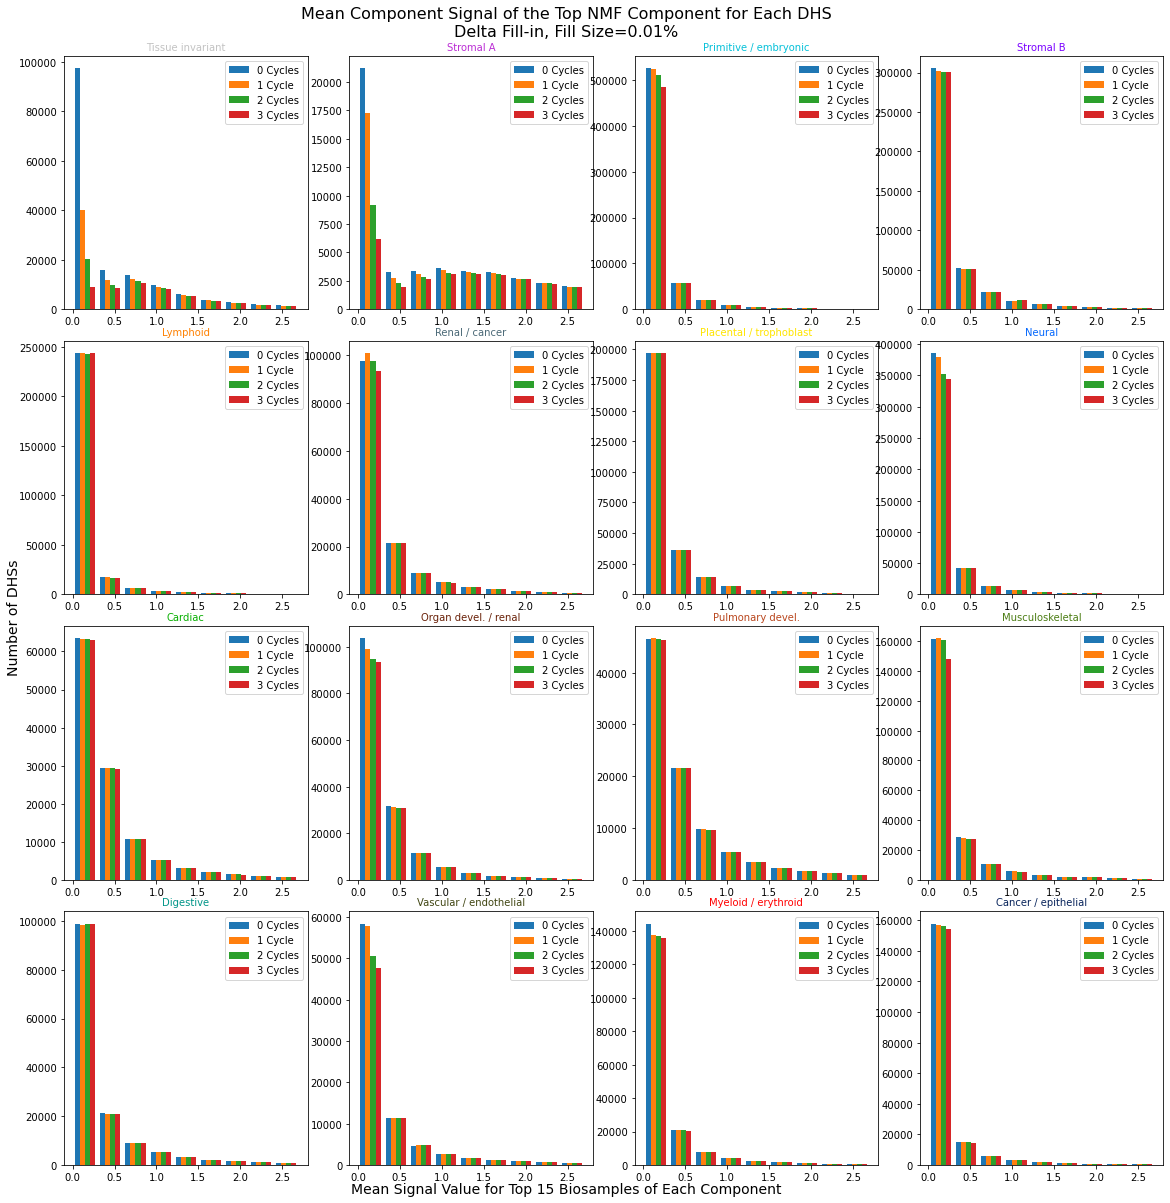

In [77]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
fig.tight_layout()
fig.patch.set_facecolor('white')

bin_max = [3, 5, 2, 2.5, 1.5, 3, 2.5, 2, 3, 3, 4, 2, 3, 3, 3, 2]

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
#     bins = range(0, int(np.ceil(max(all_comps_average_signal['comp' + str(ind) + ' mean']))), 10)
    bins = np.arange(0, 3, 0.3)
    data = [DHSs_for_each_comp_mean_comp_signal_0_cycles[ind], DHSs_for_each_comp_mean_comp_signal_1_cycle[ind], DHSs_for_each_comp_mean_comp_signal_2_cycles[ind], DHSs_for_each_comp_mean_comp_signal_3_cycles[ind]]
    ax.hist(data, bins=bins)
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
    ax.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
#     print('%s 0 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_0_cycles[ind])))
#     print('%s 1 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_1_cycle[ind])))
#     print('%s 2 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_2_cycles[ind])))
#     print('%s 3 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_3_cycles[ind])))
#     print()
    

fig.text(0.465, 0, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.465, y=1.03)

Text(0.465, 1.03, 'Average Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%')

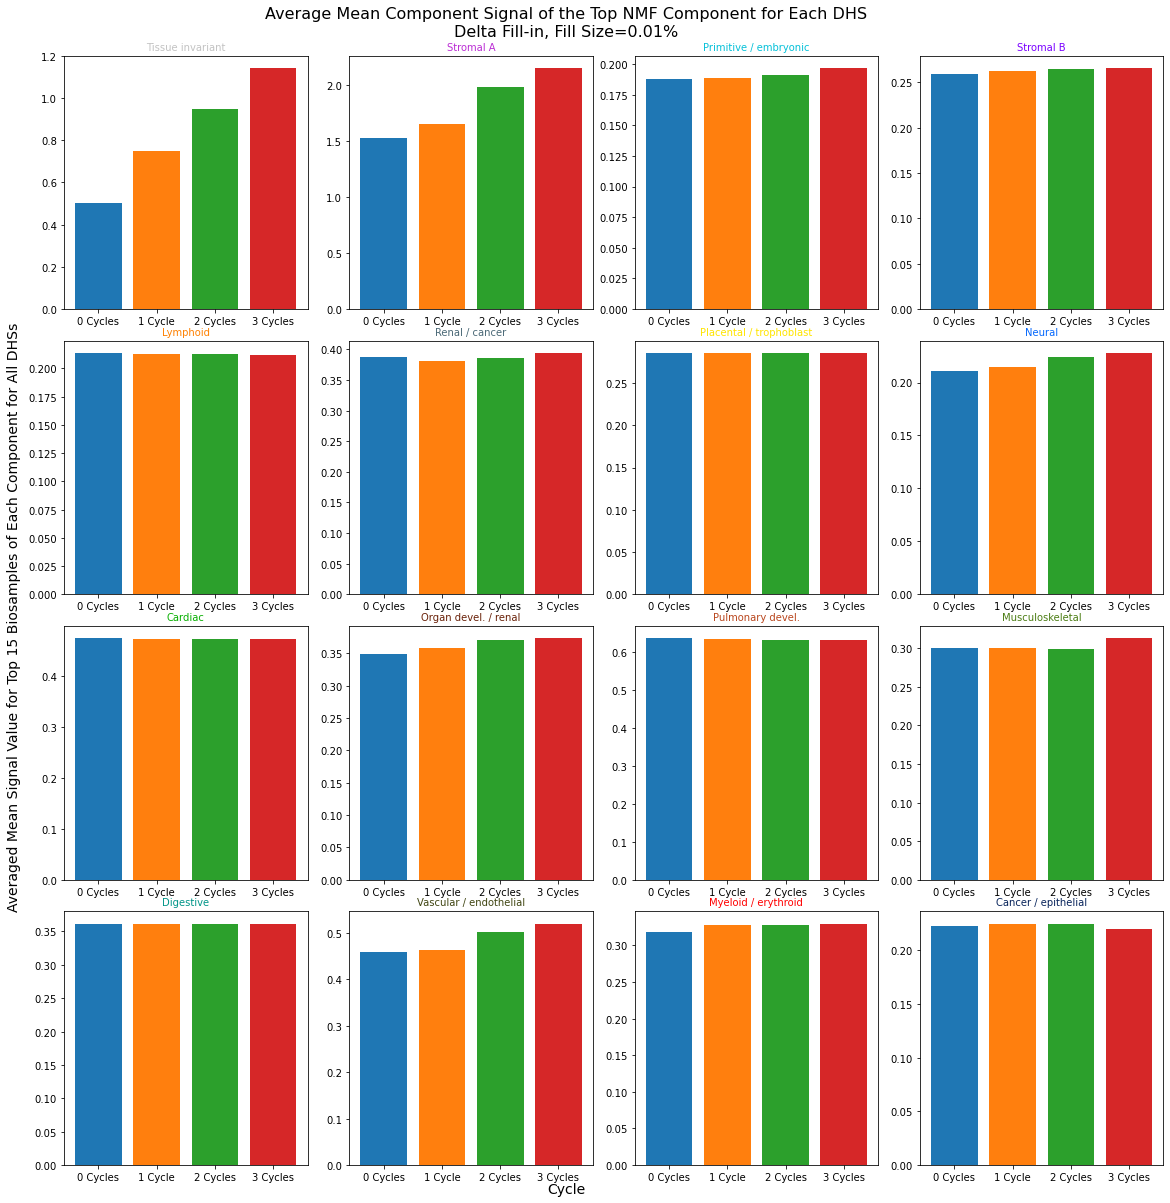

In [75]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
fig.tight_layout()
fig.patch.set_facecolor('white')

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
#     bins = range(0, int(np.ceil(max(all_comps_average_signal['comp' + str(ind) + ' mean']))), 10)
    bins = np.arange(0, 3, 0.3)
    data = [np.mean(DHSs_for_each_comp_mean_comp_signal_0_cycles[ind]), np.mean(DHSs_for_each_comp_mean_comp_signal_1_cycle[ind]), np.mean(DHSs_for_each_comp_mean_comp_signal_2_cycles[ind]), np.mean(DHSs_for_each_comp_mean_comp_signal_3_cycles[ind])]
    ax.bar(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'], data, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])

fig.text(0.465, 0, 'Cycle', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Averaged Mean Signal Value for Top 15 Biosamples of Each Component for All DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Average Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.465, y=1.03)